# Analysis results

Post-training analysis. This notebook reads the saved run JSON files and test-prediction CSV files.

# Setup

In [716]:
from pathlib import Path
from typing import Any
import json

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_DIR = Path.cwd()
RESULTS_DIR = PROJECT_DIR / "results"
EXPERIMENTS = ["v1", "v2", "v3", "v4"]
FIGURES_DIR = RESULTS_DIR / "analysis_figures"
FIGURES_DIR.mkdir(exist_ok=True)
CONDITIONS = ["regular", "augmented"]
SEEDS = [0, 1, 2, 3, 4]
assert RESULTS_DIR.exists(), f"Results directory not found: {RESULTS_DIR}"
assert all(
    (RESULTS_DIR / experiment).exists()
    for experiment in EXPERIMENTS
), "One or more experiment directories are missing"


Load one seed run from its JSON result file and test-prediction CSV.


In [717]:
def load_run(experiment: str, condition: str, seed: int, condition_dir: Path) -> dict[str, Any]:
    result_path = condition_dir / f"seed{seed}.json"
    predictions_path = condition_dir / f"seed{seed}_test_predictions.csv"
    if not result_path.exists():
        raise FileNotFoundError(result_path)
    if not predictions_path.exists():
        raise FileNotFoundError(predictions_path)
    return {
        "experiment": experiment,
        "condition": condition,
        "seed": seed,
        "result": json.loads(result_path.read_text()),
        "predictions": pd.read_csv(predictions_path),
    }

Load all requested seed runs for one condition, such as regular or augmented.


In [718]:
def load_condition(experiment: str, results_dir: Path, condition_name: str, seeds: list[int]) -> dict[str, Any]:
    experiment_dir = results_dir / experiment
    condition_dir = experiment_dir / condition_name
    if not experiment_dir.exists():
        raise FileNotFoundError(experiment_dir)
    if not condition_dir.exists():
        raise FileNotFoundError(condition_dir)
    return {
        "experiment": experiment,
        "name": condition_name,
        "runs": [load_run(experiment, condition_name, seed, condition_dir) for seed in seeds],
    }

Extract the scalar metrics from one run into a single summary record.


In [719]:
def run_summary(experiment: str, run: dict[str, Any]) -> dict[str, Any]:
    result = run["result"]
    
    return {
        "experiment": experiment,
        "condition": run["condition"],
        "seed": run["seed"],
        "best_step": result["best_step"],
        "best_val_loss": result["best_val_loss"],
        "test_loss": result["test_loss"],
        "test_accuracy": result["test_accuracy"],
        "minutes": result["minutes"],
    }

Build a table containing the scalar metrics for every run in the selected conditions.


In [720]:
def individual_runs_table(experiment: str, conditions: list[dict[str, Any]]) -> pd.DataFrame:
    return (
        pd.DataFrame([
            run_summary(experiment, run)
            for condition in conditions
            for run in condition["runs"]
        ])
        .sort_values(["experiment", "condition", "seed"])
        .reset_index(drop=True)
    )

Convert one run's validation history into a DataFrame with experiment, condition, and seed metadata.


In [721]:
def run_history(experiment: str, run: dict[str, Any]) -> pd.DataFrame:
    history = pd.DataFrame(run["result"]["history"])
    history.insert(0, "experiment", experiment)
    history.insert(1, "condition", run["condition"])
    history.insert(2, "seed", run["seed"])
    return history

Combine the validation histories from all runs in one condition.


In [722]:
def condition_history(experiment: str, condition: dict[str, Any]) -> pd.DataFrame:
    return pd.concat([run_history(experiment, run) for run in condition["runs"]], ignore_index=True)

Calculate the mean validation loss and accuracy at each training step for one condition.


In [723]:
def mean_validation_history(experiment: str, condition: dict[str, Any]) -> pd.DataFrame:
    return (
        condition_history(experiment, condition)
        .groupby(["experiment", "step"])[["train_loss", "val_loss", "val_accuracy"]]
        .mean()
        .reset_index()
    )

Calculate mean and standard deviation of test metrics grouped by experiment and condition.


In [724]:
def condition_summary(experiment: str, conditions: list[dict[str, Any]]) -> pd.DataFrame:
    runs = individual_runs_table(experiment, conditions)
    return runs.groupby(["experiment", "condition"], sort=False)[["test_accuracy", "test_loss"]].agg(["mean", "std"])

Match regular and augmented test accuracy by seed and calculate their difference.


In [725]:
def paired_accuracy(experiment: str, regular: dict[str, Any], augmented: dict[str, Any]) -> pd.DataFrame:
    paired = individual_runs_table(experiment, [regular, augmented]).pivot(
        index=["experiment", "seed"], columns="condition", values="test_accuracy"
    )
    paired["augmented_minus_regular"] = paired["augmented"] - paired["regular"]
    return paired

Combine all prediction CSV data for one condition and add experiment and condition metadata.


In [726]:
def condition_predictions(experiment: str, condition: dict[str, Any]) -> pd.DataFrame:
    predictions = pd.concat([run["predictions"] for run in condition["runs"]], ignore_index=True)
    predictions.insert(0, "experiment", experiment)
    predictions.insert(1, "condition", condition["name"])
    return predictions

Calculate the pooled true-label versus predicted-label confusion matrix for one condition.


In [727]:
def confusion_matrix(experiment: str, condition: dict[str, Any]) -> pd.DataFrame:
    predictions = condition_predictions(experiment, condition)
    classes = sorted(set(predictions["label"]) | set(predictions["predicted"]))
    return pd.crosstab(predictions["label"], predictions["predicted"]).reindex(
        index=classes, columns=classes, fill_value=0
    )

Calculate the number, correct count, and accuracy for each class in one condition.


In [728]:
def per_class_accuracy(experiment: str, condition: dict[str, Any]) -> pd.DataFrame:
    predictions = condition_predictions(experiment, condition)
    rows = []
    for label, group in predictions.groupby("label", sort=True):
        correct = group["label"] == group["predicted"]
        rows.append({
            "experiment": experiment,
            "condition": condition["name"], "class": label,
            "n_predictions": len(group), "correct": correct.sum(),
            "accuracy": correct.mean(),
        })
    return pd.DataFrame(rows)

Calculate one-vs-rest TP, FP, FN, and TN counts for every class in one condition.


In [729]:
def classification_counts(experiment: str, condition: dict[str, Any]) -> pd.DataFrame:
    predictions = condition_predictions(experiment, condition)
    rows = []
    for label in sorted(predictions["label"].unique()):
        actual_positive = predictions["label"] == label
        predicted_positive = predictions["predicted"] == label
        rows.append({
            "experiment": experiment,
            "condition": condition["name"], "class": label,
            "TP": (actual_positive & predicted_positive).sum(),
            "FP": (~actual_positive & predicted_positive).sum(),
            "FN": (actual_positive & ~predicted_positive).sum(),
            "TN": (~actual_positive & ~predicted_positive).sum(),
        })
    return pd.DataFrame(rows)

Count incorrect true-label to predicted-label pairs for one condition.


In [730]:
def confusion_pairs(experiment: str, condition: dict[str, Any]) -> pd.DataFrame:
    predictions = condition_predictions(experiment, condition)
    mistakes = predictions[predictions["label"] != predictions["predicted"]]
    return (
        mistakes.groupby(["label", "predicted"])
        .size().reset_index(name="count")
        .assign(experiment=experiment, condition=condition["name"])
    )

Plot mean validation loss and accuracy curves for one or more conditions.


In [731]:
def plot_validation_curves(experiment: str, history_by_condition: dict[str, pd.DataFrame], output_path: Path):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for condition, history_data in history_by_condition.items():
        mean_history = history_data.set_index("step")
        axes[0].plot(mean_history.index, mean_history["val_loss"], marker="o", label=condition)
        axes[1].plot(mean_history.index, mean_history["val_accuracy"], marker="o", label=condition)

    axes[0].set_title("Mean validation loss")
    axes[0].set_ylabel("Validation loss")
    axes[1].set_title("Mean validation accuracy")
    axes[1].set_ylabel("Validation accuracy")
    for ax in axes:
        ax.set_xlabel("Training step")
        ax.grid(alpha=0.25)
        ax.legend()
    fig.tight_layout()
    fig.savefig(output_path, dpi=180, bbox_inches="tight")
    plt.show()
    return fig, axes

Plot training loss against training step for each condition.


In [732]:
def plot_training_curves(experiment: str, history_by_condition: dict[str, pd.DataFrame], output_path: Path):
    fig, ax = plt.subplots(figsize=(8, 5))
    for condition, history_data in history_by_condition.items():
        mean_history = history_data.set_index("step")
        ax.plot(mean_history.index, mean_history["train_loss"], marker="o", label=f"{condition} training loss")

    ax.set_xlabel("Training step")
    ax.set_ylabel("Loss")
    ax.set_title("Training loss")
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    fig.savefig(output_path, dpi=180, bbox_inches="tight")
    plt.show()
    return fig, ax

Plot test accuracy for each seed with the condition mean and standard deviation.


In [733]:
def plot_test_accuracy_by_seed(experiment: str, runs: pd.DataFrame, conditions: list[str], output_path: Path):
    means = runs.groupby("condition")["test_accuracy"].agg(["mean", "std"]).reindex(conditions)

    fig, ax = plt.subplots(figsize=(8, 5))
    for condition in conditions:
        values = runs.loc[runs["condition"] == condition, "test_accuracy"]
        ax.plot([condition] * len(values), values, "o", label=f"{condition} runs")
        ax.errorbar(
            condition, means.loc[condition, "mean"],
            yerr=means.loc[condition, "std"],
            fmt="_", color="black", capsize=5,
            label=f"{condition} mean +/- SD",
        )

    ax.set_ylabel("Test accuracy")
    ax.set_title("Test accuracy for every seed")
    ax.set_ylim(0.5, 0.68)
    ax.grid(axis="y", alpha=0.25)
    ax.legend()
    fig.tight_layout()
    fig.savefig(output_path, dpi=180, bbox_inches="tight")
    plt.show()
    return fig, ax

Plot the augmented-minus-regular accuracy difference for each matched seed.


In [734]:
def plot_paired_accuracy_difference(experiment: str, paired: pd.DataFrame, output_path: Path):
    differences = paired["augmented_minus_regular"]
    colors = ["tab:green" if value >= 0 else "tab:red" for value in differences]

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.axhline(0, color="black", linewidth=1)
    ax.bar(differences.index.map(str), differences, color=colors)
    ax.set_xlabel("Seed")
    ax.set_ylabel("Augmented - regular accuracy")
    ax.set_title("Paired accuracy difference by seed")
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    fig.savefig(output_path, dpi=180, bbox_inches="tight")
    plt.show()
    return fig, ax

Plot one pooled confusion matrix for each supplied condition.


In [735]:
def plot_confusion_matrices(experiment: str, confusion_matrices: dict[str, pd.DataFrame], output_path: Path):
    fig, axes = plt.subplots(1, len(confusion_matrices), figsize=(12, 5), squeeze=False)
    axes = axes[0]

    for ax, (condition, matrix_frame) in zip(axes, confusion_matrices.items()):
        matrix = matrix_frame.to_numpy()
        classes = matrix_frame.index.tolist()
        image = ax.imshow(matrix, cmap="Blues")
        ax.set_xticks(range(len(classes)), classes, rotation=35, ha="right")
        ax.set_yticks(range(len(classes)), classes)
        for row in range(len(classes)):
            for column in range(len(classes)):
                ax.text(column, row, matrix[row, column], ha="center", va="center")
        fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
        ax.set_xlabel("Predicted label")
        ax.set_ylabel("True label")
        ax.set_title(f"{condition} pooled across seeds")

    fig.tight_layout()
    fig.savefig(output_path, dpi=180, bbox_inches="tight")
    plt.show()
    return fig, axes

Plot per-class accuracy for the supplied conditions.


In [736]:
def plot_per_class_accuracy(experiment: str, per_class: pd.DataFrame, conditions: list[str], output_path: Path):
    class_plot = per_class.pivot(
        index="class", columns="condition", values="accuracy"
    ).reindex(columns=conditions)

    ax = class_plot.plot(kind="bar", figsize=(8, 5), rot=25)
    ax.set_xlabel("Class")
    ax.set_ylabel("Accuracy")
    ax.set_title("Per-class accuracy by condition")
    ax.set_ylim(0, 1)
    ax.grid(axis="y", alpha=0.25)
    ax.legend(title="Condition")
    fig = ax.get_figure()
    fig.tight_layout()
    fig.savefig(output_path, dpi=180, bbox_inches="tight")
    plt.show()
    return fig, ax

Plot the most frequent pooled confusion pairs.


In [737]:
def plot_common_confusion_pairs(experiment: str, confusion_pairs: pd.DataFrame, output_path: Path):
    plot_data = (
        confusion_pairs.groupby(["label", "predicted"], as_index=False)["count"]
        .sum().sort_values("count", ascending=False).head(8)
    )
    plot_data = plot_data.copy()
    plot_data["pair"] = plot_data["label"] + " -> " + plot_data["predicted"]

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.bar(plot_data["pair"], plot_data["count"])
    ax.set_ylabel("Number of mistakes")
    ax.set_title("Most common confusion pairs")
    ax.tick_params(axis="x", rotation=35)
    fig.tight_layout()
    fig.savefig(output_path, dpi=180, bbox_inches="tight")
    plt.show()
    return fig, ax

# v1 Analysis - Model 1 - Regular and Lightly Augmented 

In [738]:
experiment = "v1"
experiment_results_dir = RESULTS_DIR / experiment
experiment_figures_dir = experiment_results_dir / "analysis_figures"
experiment_figures_dir.mkdir(exist_ok=True)
regular = load_condition(experiment, RESULTS_DIR, "regular", SEEDS)
augmented = load_condition(experiment, RESULTS_DIR, "augmented", SEEDS)

Read each saved run file and save the individual results as a CSV table.

In [739]:
runs = individual_runs_table(experiment, [regular, augmented])
runs.to_csv(experiment_results_dir / "analysis_individual_runs.csv", index=False)
display(runs.style.format({"best_val_loss": "{:.4f}", "test_loss": "{:.4f}", "test_accuracy": "{:.4f}", "minutes": "{:.1f}"}))

,experiment,condition,seed,best_step,best_val_loss,test_loss,test_accuracy,minutes
0,v1,augmented,0,50,1.3613,1.3903,0.5564,19.9
1,v1,augmented,1,100,1.1052,1.1161,0.6170,23.8
2,v1,augmented,2,100,1.3118,1.2408,0.6057,23.4
3,v1,augmented,3,300,1.2518,1.3519,0.6360,38.0
4,v1,augmented,4,150,1.3103,1.2935,0.5904,27.5
5,v1,regular,0,100,1.2076,1.2733,0.5809,22.9
6,v1,regular,1,100,1.0270,1.0812,0.6272,23.6
7,v1,regular,2,100,1.3036,1.3341,0.5641,23.2
8,v1,regular,3,150,1.2237,1.2870,0.6104,27.0
9,v1,regular,4,50,1.1855,1.2146,0.5929,19.6


## Individual-run comparison

Validation loss selected the checkpoint. Test metrics were calculated after that selection and are retained for every seed.

In [740]:
summary = condition_summary(experiment, [regular, augmented])
paired = paired_accuracy(experiment, regular, augmented)
display(summary)
display(paired)
print(f"Mean paired accuracy difference: {paired['augmented_minus_regular'].mean():.4f}")

test_accuracy           test_loss          
                              mean       std      mean       std
experiment condition                                            
v1         augmented      0.601095  0.030021  1.278522  0.107110
           regular        0.595108  0.024688  1.238042  0.097482

condition        augmented   regular  augmented_minus_regular
experiment seed                                              
v1         0      0.556407  0.580869                -0.024462
           1      0.617014  0.627236                -0.010223
           2      0.605695  0.564074                 0.041621
           3      0.635999  0.610442                 0.025557
           4      0.590361  0.592917                -0.002556

Mean paired accuracy difference: 0.0060


The augmented dataset accumulated a fractional higher mean test accuracy than the regular dataset. The regular dataset also had a lower test loss. This could be for various reasons one it could possibly be a signal that the augmented dataset generalises better.

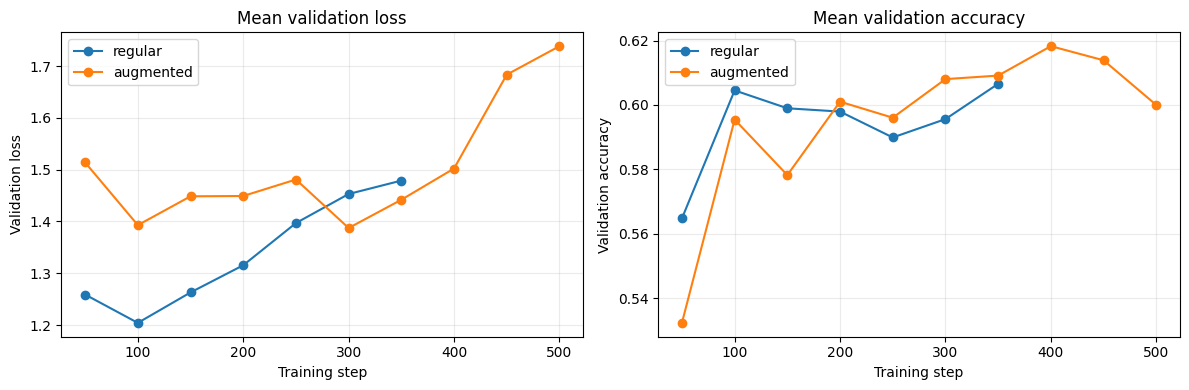

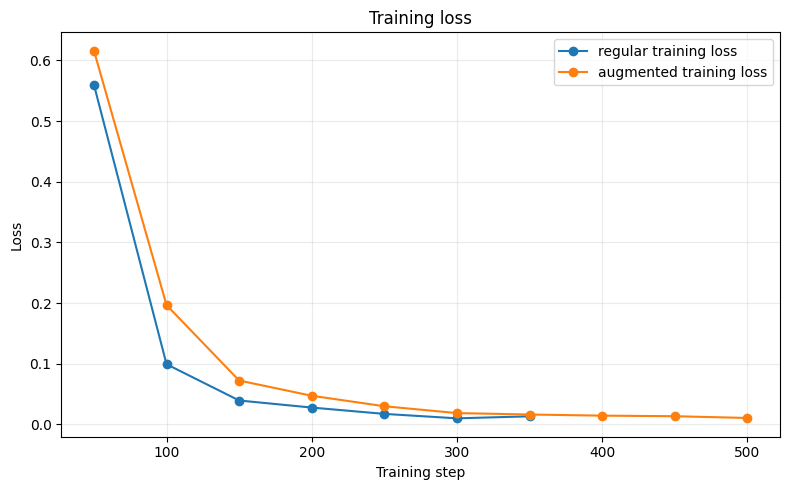

,mean,std
condition,,
augmented,140.0,96.176920
regular,100.0,35.355339


In [741]:
history_by_condition = {
    "regular": mean_validation_history(experiment, regular),
    "augmented": mean_validation_history(experiment, augmented),
}
plot_validation_curves(experiment, history_by_condition, experiment_figures_dir / "validation_curves.png")
plot_training_curves(experiment, history_by_condition, experiment_figures_dir / "training_curves.png")

best_steps = runs.groupby("condition")["best_step"].agg(["mean", "std"])
display(best_steps)

##### Validation Loss
The regular model starts with lower validation loss, reaching its lowest average loss at roughly 100 training steps.
Its loss then gradually increases, suggesting that training beyond this point may be causing overfitting.

The augmented model starts with a higher loss, improves early, and is briefly similar to the regular model around 300 steps.
After about 350 steps, the augmented model's loss rises sharply, indicating that later training became worse rather than better.

##### Validation Accuracy
Both conditions reach validation accuracies around 0.59-0.62.
The augmented model catches up with, and sometimes exceeds, the regular model at later steps.
However, the improvement is small and inconsistent across the training curve. It does not show a fully stable upward advantage for augmentation.

Accuracy fluctuates while loss increases, which suggests that the model may still classify some examples correctly but is becoming increasingly uncertain or making more confident errors.

##### Conclusion
Both models learn useful features early, but continuing training does not consistently improve validation performance. Augmentation gives slightly better validation accuracy at some later checkpoints, but it also has higher and more unstable validation loss. Therefore, these curves do not provide strong evidence that augmentation improved training.

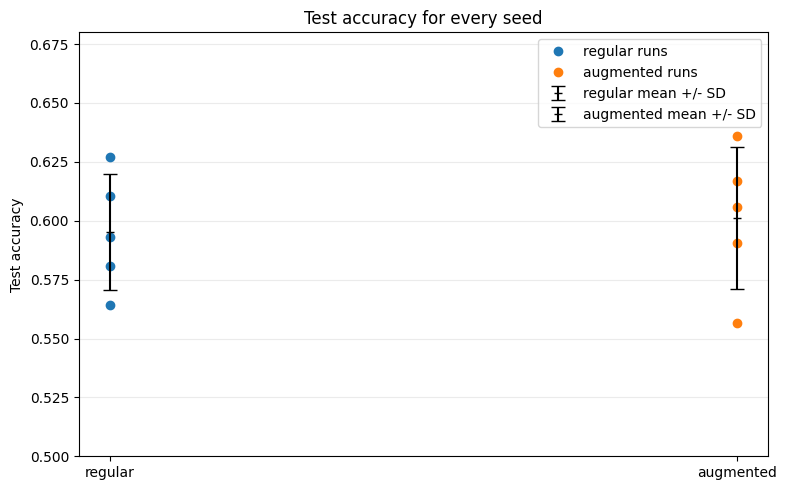

(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'Test accuracy for every seed'}, ylabel='Test accuracy'>)

In [742]:
plot_test_accuracy_by_seed(
    experiment, runs,
    CONDITIONS,
    experiment_figures_dir / "test_accuracy_by_seed.png",
)

This plot shows the test accuracy for every seed in both conditions, together with each condition's mean and standard deviation. The augmented mean is only slightly higher than the regular mean, and the points overlap substantially. This tells us that augmentation does not produce a clear or consistent overall accuracy improvement across the five seeds.

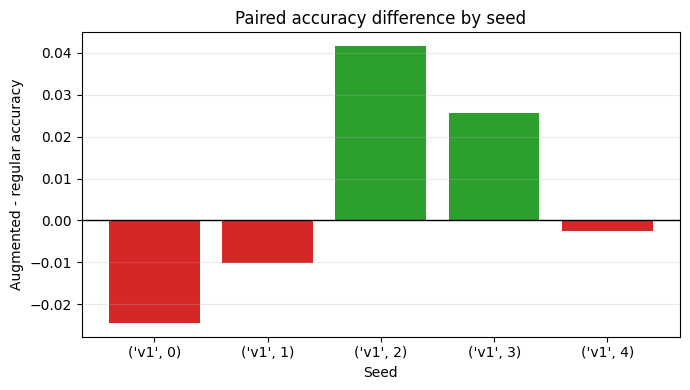

(<Figure size 700x400 with 1 Axes>,
 <Axes: title={'center': 'Paired accuracy difference by seed'}, xlabel='Seed', ylabel='Augmented - regular accuracy'>)

In [743]:
plot_paired_accuracy_difference(
    experiment, paired,
    experiment_figures_dir / "paired_accuracy_difference.png",
)

Each bar shows how augmentation changed accuracy for the same seed. Positive bars mean augmentation helped; negative bars mean it hurt. The bars appear on both sides of zero, showing that the small average improvement is not consistent across seeds and should not be described as a reliable effect.

## Anomalies and failure cases

The class labels mean: `tom` = Tom in frame, `jerry` = Jerry in frame, `tom_jerry_0` = neither Tom nor Jerry in frame, and `tom_jerry_1` = both Tom and Jerry in frame. The confusion matrices and per-class table identify whether the overall metric hides class-specific failures.

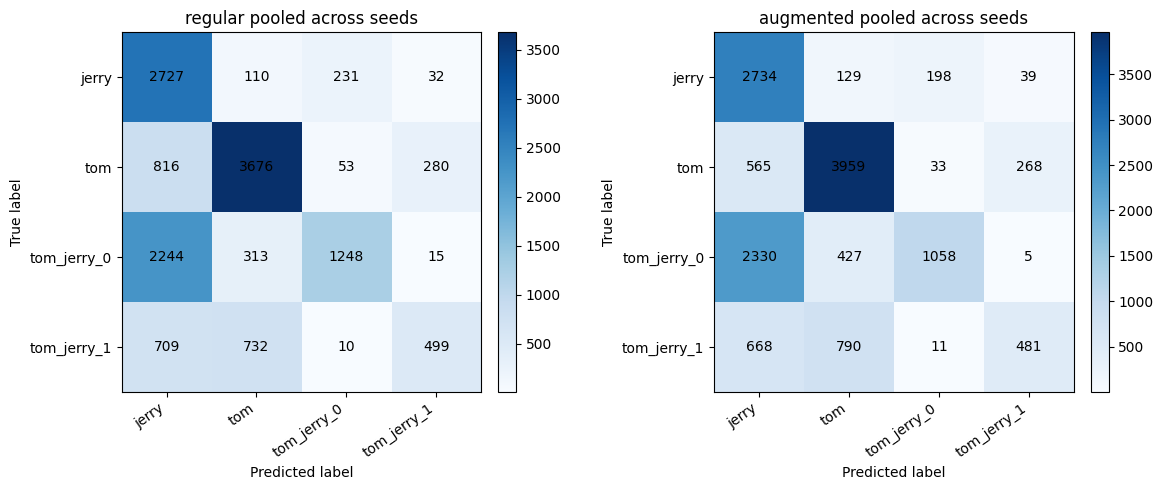

condition,augmented,regular
class,,
jerry,0.881935,0.879677
tom,0.820518,0.761865
tom_jerry_0,0.276963,0.326702
tom_jerry_1,0.246667,0.255897


In [744]:
confusion_matrices = {
    condition["name"]: confusion_matrix(experiment, condition)
    for condition in [regular, augmented]
}
plot_confusion_matrices(
    experiment, confusion_matrices,
    experiment_figures_dir / "pooled_confusion_matrices.png",
)

per_class = pd.concat(
    [per_class_accuracy(experiment, regular), per_class_accuracy(experiment, augmented)],
    ignore_index=True,
)
per_class.to_csv(experiment_results_dir / "analysis_per_class_accuracy.csv", index=False)
display(per_class.pivot(index="class", columns="condition", values="accuracy"))

These pooled confusion matrices show which classes are predicted correctly and which are confused. The model recognises frames containing Tom or Jerry more successfully, while frames containing neither character and frames containing both characters are much harder. This reveals important class-specific failures that overall accuracy hides.

This text table breaks each class into true positives (TP), false positives (FP), false negatives (FN), and true negatives (TN). The counts use a one-vs-rest view: the selected class is treated as positive and all other classes as negative.

In [745]:
classification_counts_table = pd.concat(
    [classification_counts(experiment, regular), classification_counts(experiment, augmented)],
    ignore_index=True,
)
display(classification_counts_table)

,experiment,condition,class,TP,FP,FN,TN
0,v1,regular,jerry,2727,3769,373,6826
1,v1,regular,tom,3676,1155,1149,7715
2,v1,regular,tom_jerry_0,1248,294,2572,9581
3,v1,regular,tom_jerry_1,499,327,1451,11418
4,v1,augmented,jerry,2734,3563,366,7032
5,v1,augmented,tom,3959,1346,866,7524
6,v1,augmented,tom_jerry_0,1058,242,2762,9633
7,v1,augmented,tom_jerry_1,481,312,1469,11433


Compare per-class accuracy directly to show which classes gained or lost under augmentation.

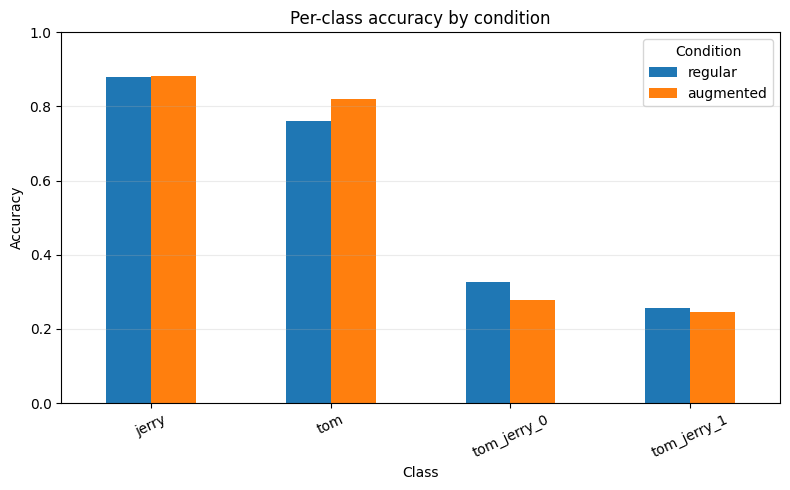

(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'Per-class accuracy by condition'}, xlabel='Class', ylabel='Accuracy'>)

In [746]:
plot_per_class_accuracy(
    experiment, per_class,
    CONDITIONS,
    experiment_figures_dir / "per_class_accuracy.png",
)

Augmentation improves the Tom class, but performance remains weak for frames containing neither character and frames containing both characters. The result suggests that augmentation may help one relatively recognisable class without solving the harder task of distinguishing the two special frame types.

,label,predicted,count,experiment,condition
18,tom_jerry_0,jerry,2330,v1,augmented
22,tom_jerry_1,tom,790,v1,augmented
21,tom_jerry_1,jerry,668,v1,augmented
15,tom,jerry,565,v1,augmented
19,tom_jerry_0,tom,427,v1,augmented
6,tom_jerry_0,jerry,2244,v1,regular
3,tom,jerry,816,v1,regular
10,tom_jerry_1,tom,732,v1,regular
9,tom_jerry_1,jerry,709,v1,regular
7,tom_jerry_0,tom,313,v1,regular


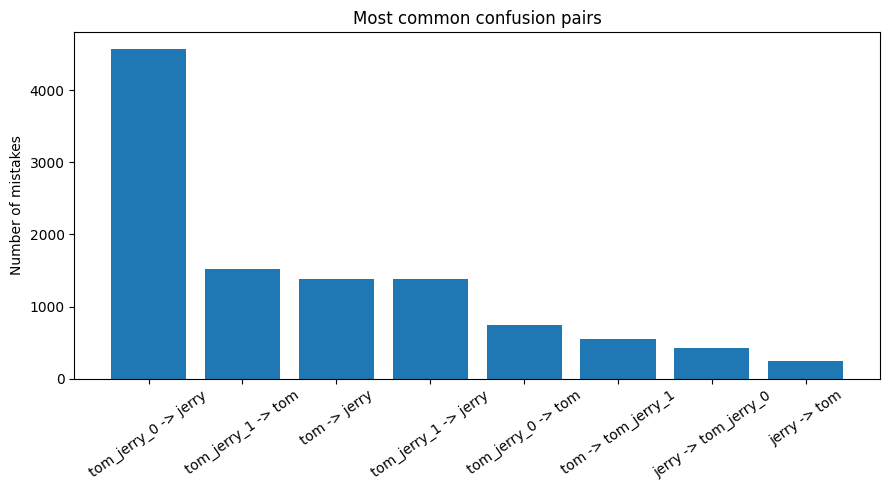

(<Figure size 900x500 with 1 Axes>,
 <Axes: title={'center': 'Most common confusion pairs'}, ylabel='Number of mistakes'>)

In [747]:
confusion_pairs_table = pd.concat(
    [confusion_pairs(experiment, regular), confusion_pairs(experiment, augmented)],
    ignore_index=True,
).sort_values(["condition", "count"], ascending=[True, False])
confusion_pairs_table.to_csv(
    experiment_results_dir / "analysis_common_confusion_pairs.csv",
    index=False,
)
display(confusion_pairs_table.groupby("condition", group_keys=False).head(5))
plot_common_confusion_pairs(
    experiment, confusion_pairs_table,
    experiment_figures_dir / "common_confusion_pairs.png",
)

,label,predicted,count,experiment,condition
18,tom_jerry_0,jerry,2330,v1,augmented
22,tom_jerry_1,tom,790,v1,augmented
21,tom_jerry_1,jerry,668,v1,augmented
15,tom,jerry,565,v1,augmented
19,tom_jerry_0,tom,427,v1,augmented
6,tom_jerry_0,jerry,2244,v1,regular
3,tom,jerry,816,v1,regular
10,tom_jerry_1,tom,732,v1,regular
9,tom_jerry_1,jerry,709,v1,regular
7,tom_jerry_0,tom,313,v1,regular


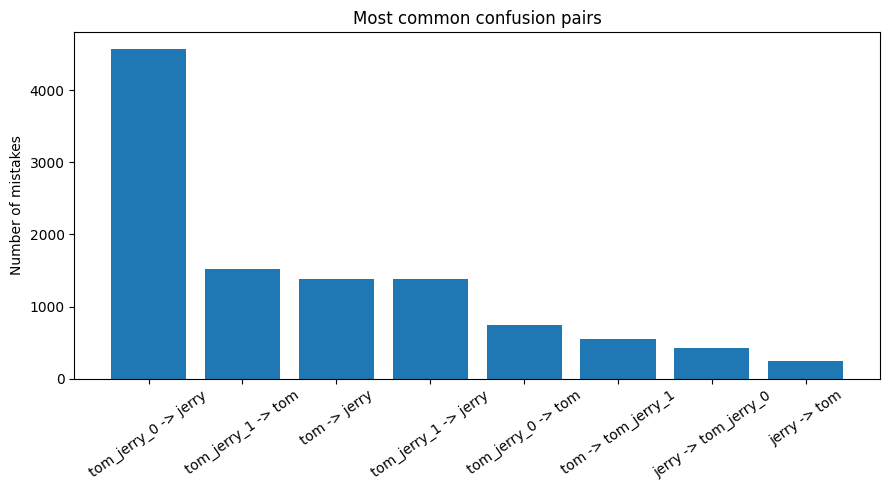

(<Figure size 900x500 with 1 Axes>,
 <Axes: title={'center': 'Most common confusion pairs'}, ylabel='Number of mistakes'>)

In [ ]:
confusion_pairs_table = pd.concat(
    [confusion_pairs(experiment, regular), confusion_pairs(experiment, augmented)],
    ignore_index=True,
).sort_values(["condition", "count"], ascending=[True, False])
confusion_pairs_table.to_csv(
    experiment_results_dir / "analysis_common_confusion_pairs.csv",
    index=False,
)
display(confusion_pairs_table.groupby("condition", group_keys=False).head(5))
plot_common_confusion_pairs(
    experiment, confusion_pairs_table,
    experiment_figures_dir / "common_confusion_pairs.png",
)

The most frequent pooled mistakes are especially frames containing neither character being predicted as Jerry or Tom. It confirms which errors dominate the dataset, but these are raw counts and are affected by class frequency. The per-class accuracy and normalised confusion matrix should therefore be used to judge class-specific performance.

## v1 interpretation

Across five matched seeds, augmentation has a slightly higher mean test accuracy than the regular reference condition (about 0.601 versus 0.595), but the paired difference is small and changes direction across seeds. Augmentation also has a higher mean test loss (about 1.279 versus 1.238). The overall metrics therefore do not establish a reliable improvement in generalisation from augmentation.

The validation curves show useful learning early in training, followed by a plateau or deterioration rather than a steady improvement. Validation loss rises at later checkpoints, especially for the augmented condition, while validation accuracy fluctuates around the same level. This supports selecting the best validation checkpoint instead of using the final checkpoint. The test-loss plot and paired-difference plot also show that the small average accuracy advantage is not consistent across seeds.

The clearest failure is class-specific. Frames containing Tom or Jerry are classified much more accurately, while `tom_jerry_0` (neither character in frame) and `tom_jerry_1` (both characters in frame) are frequently confused with the single-character classes. The one-vs-rest TP/FP/FN/TN table makes this explicit: false negatives are high for the difficult classes, while false positives show that the model often predicts `tom` or `jerry` when the true image contains neither or both. The largest pooled error is `tom_jerry_0` being predicted as `jerry`, although raw counts are affected by class frequency. Overall accuracy therefore hides an important weakness in recognising the combined-character states, so the confusion matrices, per-class accuracy, and TP/FP/FN/TN counts should be reported alongside the run-level results.

Overall, augmentation appears broadly comparable to the regular condition, with a small but unreliable accuracy advantage and no clear improvement in loss or class-level robustness.

# v2 Analysis - Model 1 - Regular and Heavier Augmented


In [748]:
experiment = "v2"
experiment_results_dir = RESULTS_DIR / experiment
experiment_figures_dir = experiment_results_dir / "analysis_figures"
experiment_figures_dir.mkdir(exist_ok=True)
regular = load_condition(experiment, RESULTS_DIR, "regular", SEEDS)
augmented = load_condition(experiment, RESULTS_DIR, "augmented", SEEDS)

Read each v2 saved run file and save the individual results as a CSV table.


In [749]:
runs = individual_runs_table(experiment, [regular, augmented])
runs.to_csv(experiment_results_dir / "analysis_individual_runs.csv", index=False)
display(runs.style.format({"best_val_loss": "{:.4f}", "test_loss": "{:.4f}", "test_accuracy": "{:.4f}", "minutes": "{:.1f}"}))

,experiment,condition,seed,best_step,best_val_loss,test_loss,test_accuracy,minutes
0,v2,augmented,0,400,1.2651,1.3498,0.5933,52.4
1,v2,augmented,1,100,1.2447,1.0596,0.6345,24.4
2,v2,augmented,2,50,1.4724,1.4631,0.5276,20.7
3,v2,augmented,3,100,1.2534,1.3298,0.6083,21.4
4,v2,augmented,4,200,1.3438,1.2634,0.6247,26.5
5,v2,regular,0,100,1.2076,1.2733,0.5809,22.9
6,v2,regular,1,100,1.0270,1.0812,0.6272,23.6
7,v2,regular,2,100,1.3036,1.3341,0.5641,23.2
8,v2,regular,3,150,1.2237,1.2870,0.6104,27.0
9,v2,regular,4,50,1.1855,1.2146,0.5929,19.6


Calculate v2 condition-level summaries and compare accuracy for matched seeds.


In [750]:
summary = condition_summary(experiment, [regular, augmented])
paired = paired_accuracy(experiment, regular, augmented)
display(summary)
display(paired)
print(f"Mean paired accuracy difference: {paired['augmented_minus_regular'].mean():.4f}")

test_accuracy           test_loss          
                              mean       std      mean       std
experiment condition                                            
v2         augmented      0.597663  0.042234  1.293143  0.149077
           regular        0.595108  0.024688  1.238042  0.097482

condition        augmented   regular  augmented_minus_regular
experiment seed                                              
v2         0      0.593282  0.580869                 0.012413
           1      0.634538  0.627236                 0.007302
           2      0.527565  0.564074                -0.036510
           3      0.608251  0.610442                -0.002191
           4      0.624681  0.592917                 0.031763

Mean paired accuracy difference: 0.0026


Plot v2 validation loss and accuracy curves.


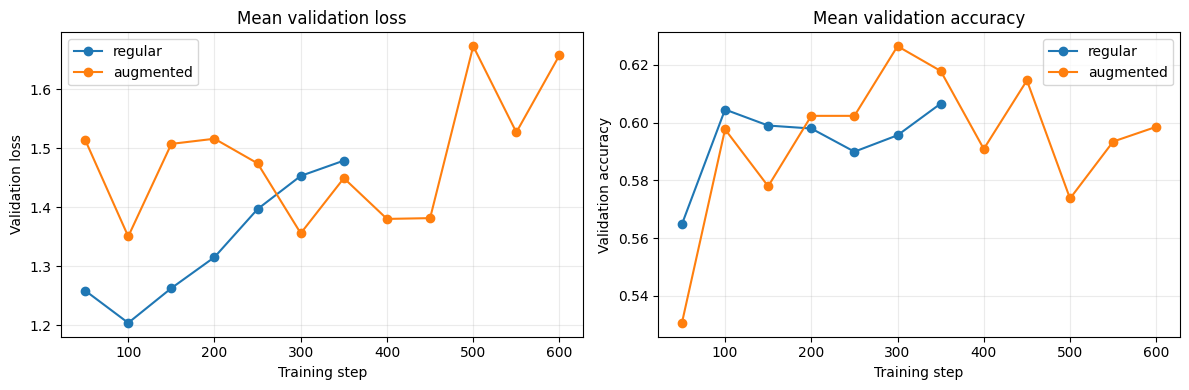

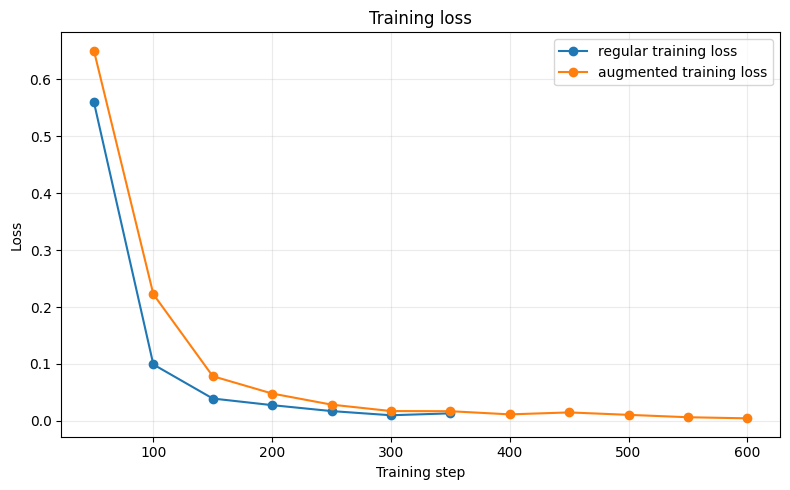

mean         std
experiment condition                   
v2         augmented  170.0  139.642400
           regular    100.0   35.355339

In [751]:
history_by_condition = {
    "regular": mean_validation_history(experiment, regular),
    "augmented": mean_validation_history(experiment, augmented),
}
plot_validation_curves(experiment, history_by_condition, experiment_figures_dir / "validation_curves.png")
plot_training_curves(experiment, history_by_condition, experiment_figures_dir / "training_curves.png")

best_steps = runs.groupby(["experiment", "condition"])["best_step"].agg(["mean", "std"])
display(best_steps)

Plot v2 test accuracy for each seed with condition mean and standard deviation.


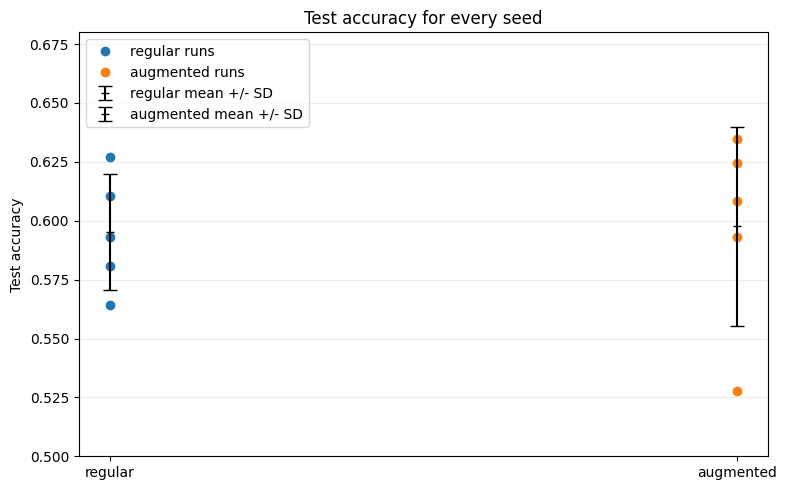

(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'Test accuracy for every seed'}, ylabel='Test accuracy'>)

In [752]:
plot_test_accuracy_by_seed(
    experiment, runs, CONDITIONS,
    experiment_figures_dir / "test_accuracy_by_seed.png",
)

Plot the v2 paired accuracy difference for each matched seed.


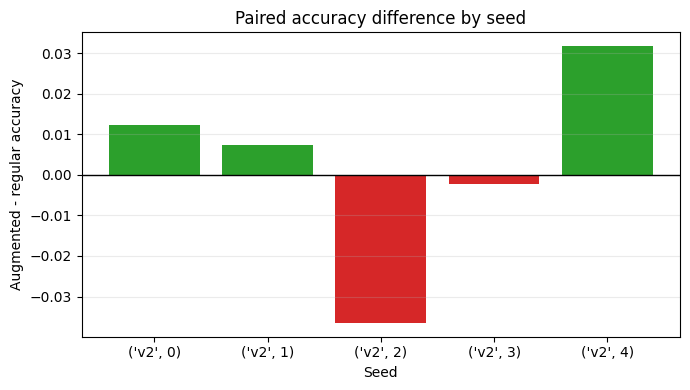

(<Figure size 700x400 with 1 Axes>,
 <Axes: title={'center': 'Paired accuracy difference by seed'}, xlabel='Seed', ylabel='Augmented - regular accuracy'>)

In [753]:
plot_paired_accuracy_difference(
    experiment, paired,
    experiment_figures_dir / "paired_accuracy_difference.png",
)

Create v2 pooled confusion matrices and per-class accuracy.


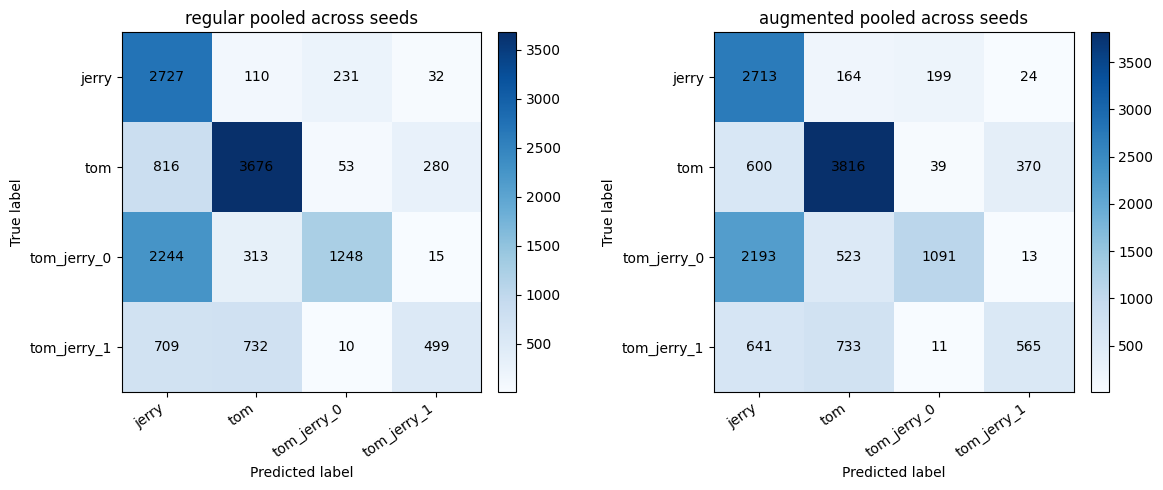

condition,augmented,regular
class,,
jerry,0.875161,0.879677
tom,0.790881,0.761865
tom_jerry_0,0.285602,0.326702
tom_jerry_1,0.289744,0.255897


In [754]:
confusion_matrices = {
    condition["name"]: confusion_matrix(experiment, condition)
    for condition in [regular, augmented]
}
plot_confusion_matrices(
    experiment, confusion_matrices,
    experiment_figures_dir / "pooled_confusion_matrices.png",
)
per_class = pd.concat(
    [per_class_accuracy(experiment, regular), per_class_accuracy(experiment, augmented)],
    ignore_index=True,
)
per_class.to_csv(experiment_results_dir / "analysis_per_class_accuracy.csv", index=False)
display(per_class.pivot(index="class", columns="condition", values="accuracy"))

Show v2 classification counts and per-class accuracy.


,experiment,condition,class,TP,FP,FN,TN
0,v2,regular,jerry,2727,3769,373,6826
1,v2,regular,tom,3676,1155,1149,7715
2,v2,regular,tom_jerry_0,1248,294,2572,9581
3,v2,regular,tom_jerry_1,499,327,1451,11418
4,v2,augmented,jerry,2713,3434,387,7161
5,v2,augmented,tom,3816,1420,1009,7450
6,v2,augmented,tom_jerry_0,1091,249,2729,9626
7,v2,augmented,tom_jerry_1,565,407,1385,11338


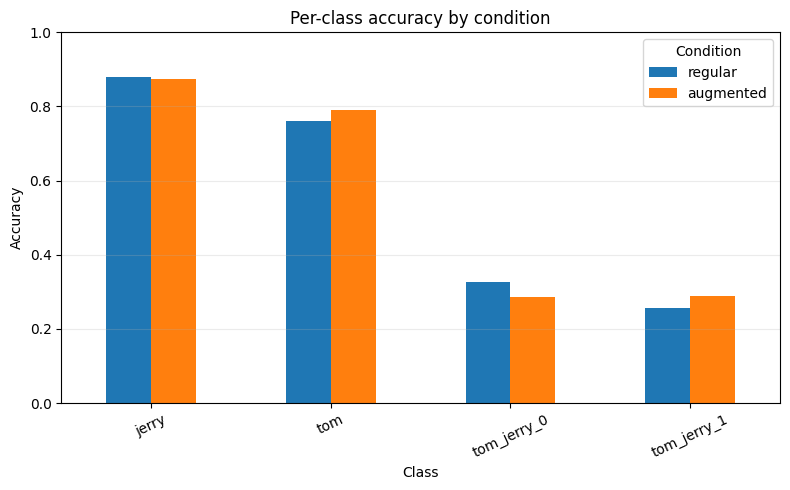

(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'Per-class accuracy by condition'}, xlabel='Class', ylabel='Accuracy'>)

In [755]:
classification_counts_table = pd.concat(
    [classification_counts(experiment, regular), classification_counts(experiment, augmented)],
    ignore_index=True,
)
display(classification_counts_table)
plot_per_class_accuracy(
    experiment, per_class, CONDITIONS,
    experiment_figures_dir / "per_class_accuracy.png",
)

Rank and plot the most common v2 confusion pairs.


,label,predicted,count,experiment,condition
18,tom_jerry_0,jerry,2193,v2,augmented
22,tom_jerry_1,tom,733,v2,augmented
21,tom_jerry_1,jerry,641,v2,augmented
15,tom,jerry,600,v2,augmented
19,tom_jerry_0,tom,523,v2,augmented
6,tom_jerry_0,jerry,2244,v2,regular
3,tom,jerry,816,v2,regular
10,tom_jerry_1,tom,732,v2,regular
9,tom_jerry_1,jerry,709,v2,regular
7,tom_jerry_0,tom,313,v2,regular


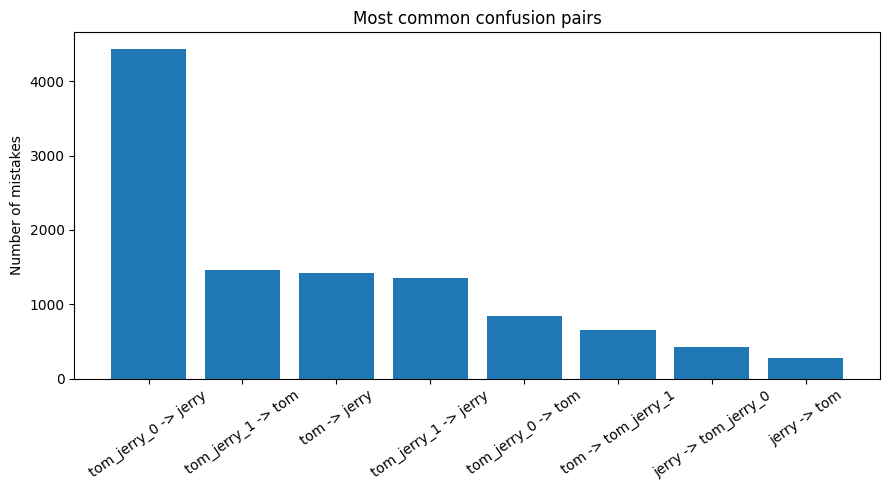

(<Figure size 900x500 with 1 Axes>,
 <Axes: title={'center': 'Most common confusion pairs'}, ylabel='Number of mistakes'>)

In [756]:
confusion_pairs_table = pd.concat(
    [confusion_pairs(experiment, regular), confusion_pairs(experiment, augmented)],
    ignore_index=True,
).sort_values(["experiment", "condition", "count"], ascending=[True, True, False])
confusion_pairs_table.to_csv(
    experiment_results_dir / "analysis_common_confusion_pairs.csv",
    index=False,
)
display(confusion_pairs_table.groupby("condition", group_keys=False).head(5))
plot_common_confusion_pairs(
    experiment, confusion_pairs_table,
    experiment_figures_dir / "common_confusion_pairs.png",
)

## v2 interpretation

V2 uses the Model 1 setup with heavier augmentation. Across the five matched seeds, the augmented condition has a mean test accuracy of about 0.598 compared with 0.595 for regular training. The mean paired accuracy difference is only about 0.003, so the overall accuracy advantage is very small and should not be treated as strong evidence of improved generalisation.

The augmented condition has a higher mean test loss, about 1.293 compared with 1.238 for regular training, and its best checkpoints occur later on average. This suggests that heavier augmentation changes the optimisation behaviour, but does not clearly improve the final loss-based result.

The class-level results are mixed. Augmentation slightly reduces Jerry accuracy and improves Tom accuracy, while the difficult combined-character classes remain weak. `tom_jerry_0` is lower under augmentation, while `tom_jerry_1` is higher. The confusion-pair table should therefore be used alongside overall accuracy because the average result hides these class-specific changes.

Overall, v2 is broadly comparable to regular training. Heavier augmentation produces a negligible average accuracy change, a higher mean test loss, and mixed effects across classes.


# v3 Analysis - Model 2 - Regular and Lightly Augmented


In [757]:
experiment = "v3"
experiment_results_dir = RESULTS_DIR / experiment
experiment_figures_dir = experiment_results_dir / "analysis_figures"
experiment_figures_dir.mkdir(exist_ok=True)
regular = load_condition(experiment, RESULTS_DIR, "regular", SEEDS)
augmented = load_condition(experiment, RESULTS_DIR, "augmented", SEEDS)

Read each v3 saved run file and save the individual results as a CSV table.


In [758]:
runs = individual_runs_table(experiment, [regular, augmented])
runs.to_csv(experiment_results_dir / "analysis_individual_runs.csv", index=False)
display(runs.style.format({"best_val_loss": "{:.4f}", "test_loss": "{:.4f}", "test_accuracy": "{:.4f}", "minutes": "{:.1f}"}))

,experiment,condition,seed,best_step,best_val_loss,test_loss,test_accuracy,minutes
0,v3,augmented,0,300,1.0824,1.0591,0.5860,65.2
1,v3,augmented,1,300,0.9675,0.9516,0.6221,45.9
2,v3,augmented,2,250,1.0817,1.0572,0.5568,30.4
3,v3,augmented,3,400,1.0434,1.0319,0.6057,39.8
4,v3,augmented,4,550,1.0435,1.0492,0.5944,40.2
5,v3,regular,0,300,1.1582,1.1899,0.5363,60.0
6,v3,regular,1,200,1.0436,1.0464,0.5652,41.7
7,v3,regular,2,150,1.1608,1.1642,0.5144,27.5
8,v3,regular,3,450,1.1088,1.0923,0.5750,40.8
9,v3,regular,4,600,1.1034,1.1346,0.5484,39.7


Calculate v3 condition-level summaries and compare accuracy for matched seeds.


In [759]:
summary = condition_summary(experiment, [regular, augmented])
paired = paired_accuracy(experiment, regular, augmented)
display(summary)
display(paired)
print(f"Mean paired accuracy difference: {paired['augmented_minus_regular'].mean():.4f}")

test_accuracy           test_loss          
                              mean       std      mean       std
experiment condition                                            
v3         augmented      0.592990  0.024357  1.029814  0.045017
           regular        0.547864  0.023922  1.125476  0.057212

condition        augmented   regular  augmented_minus_regular
experiment seed                                              
v3         0      0.585980  0.536327                 0.049653
           1      0.622125  0.565170                 0.056955
           2      0.556773  0.514421                 0.042351
           3      0.605695  0.575027                 0.030668
           4      0.594378  0.548375                 0.046002

Mean paired accuracy difference: 0.0451


Plot v3 validation loss and accuracy curves.


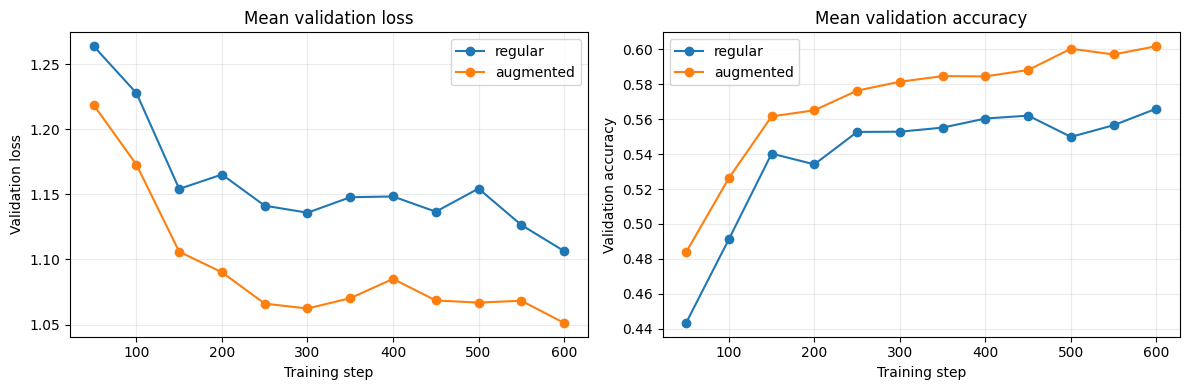

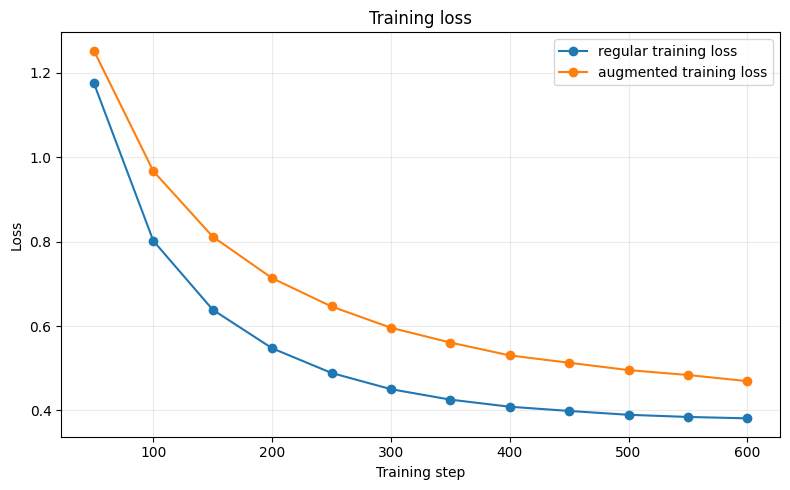

mean         std
experiment condition                   
v3         augmented  360.0  119.373364
           regular    340.0  185.067555

In [760]:
history_by_condition = {
    "regular": mean_validation_history(experiment, regular),
    "augmented": mean_validation_history(experiment, augmented),
}
plot_validation_curves(experiment, history_by_condition, experiment_figures_dir / "validation_curves.png")
plot_training_curves(experiment, history_by_condition, experiment_figures_dir / "training_curves.png")

best_steps = runs.groupby(["experiment", "condition"])["best_step"].agg(["mean", "std"])
display(best_steps)

Plot v3 test accuracy for each seed with condition mean and standard deviation.


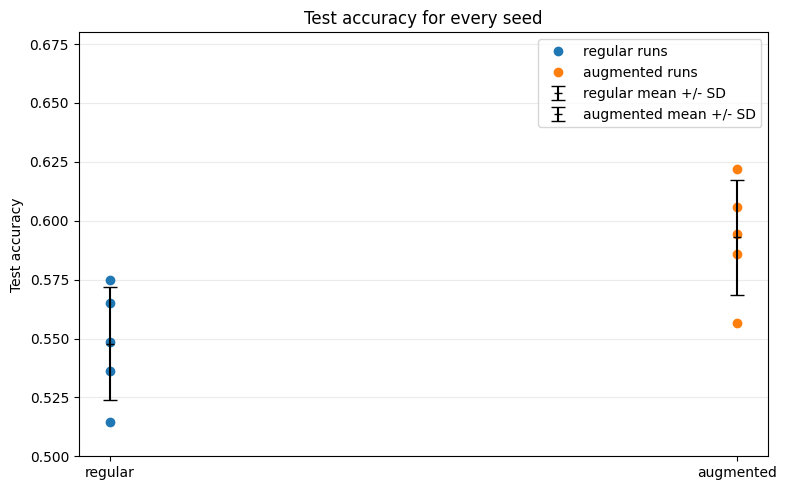

(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'Test accuracy for every seed'}, ylabel='Test accuracy'>)

In [761]:
plot_test_accuracy_by_seed(
    experiment, runs, CONDITIONS,
    experiment_figures_dir / "test_accuracy_by_seed.png",
)

Plot the v3 paired accuracy difference for each matched seed.


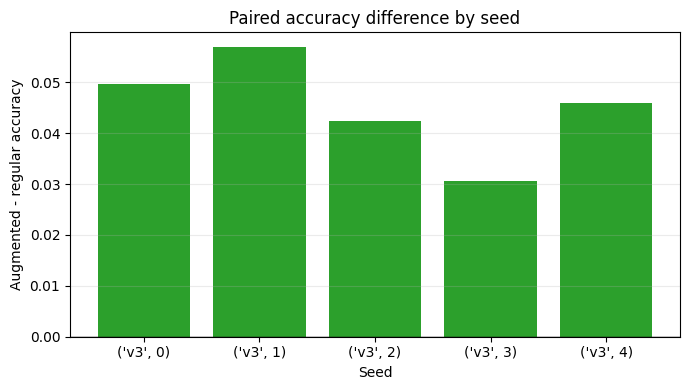

(<Figure size 700x400 with 1 Axes>,
 <Axes: title={'center': 'Paired accuracy difference by seed'}, xlabel='Seed', ylabel='Augmented - regular accuracy'>)

In [762]:
plot_paired_accuracy_difference(
    experiment, paired,
    experiment_figures_dir / "paired_accuracy_difference.png",
)

Create v3 pooled confusion matrices and per-class accuracy.


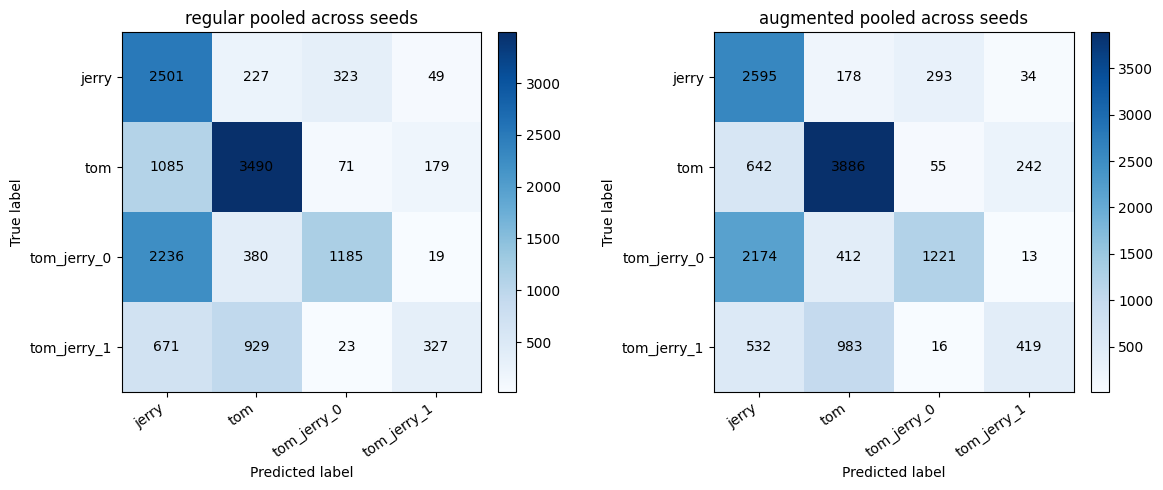

condition,augmented,regular
class,,
jerry,0.837097,0.806774
tom,0.805389,0.723316
tom_jerry_0,0.319634,0.310209
tom_jerry_1,0.214872,0.167692


In [763]:
confusion_matrices = {
    condition["name"]: confusion_matrix(experiment, condition)
    for condition in [regular, augmented]
}
plot_confusion_matrices(
    experiment, confusion_matrices,
    experiment_figures_dir / "pooled_confusion_matrices.png",
)
per_class = pd.concat(
    [per_class_accuracy(experiment, regular), per_class_accuracy(experiment, augmented)],
    ignore_index=True,
)
per_class.to_csv(experiment_results_dir / "analysis_per_class_accuracy.csv", index=False)
display(per_class.pivot(index="class", columns="condition", values="accuracy"))

Show v3 classification counts and per-class accuracy.


,experiment,condition,class,TP,FP,FN,TN
0,v3,regular,jerry,2501,3992,599,6603
1,v3,regular,tom,3490,1536,1335,7334
2,v3,regular,tom_jerry_0,1185,417,2635,9458
3,v3,regular,tom_jerry_1,327,247,1623,11498
4,v3,augmented,jerry,2595,3348,505,7247
5,v3,augmented,tom,3886,1573,939,7297
6,v3,augmented,tom_jerry_0,1221,364,2599,9511
7,v3,augmented,tom_jerry_1,419,289,1531,11456


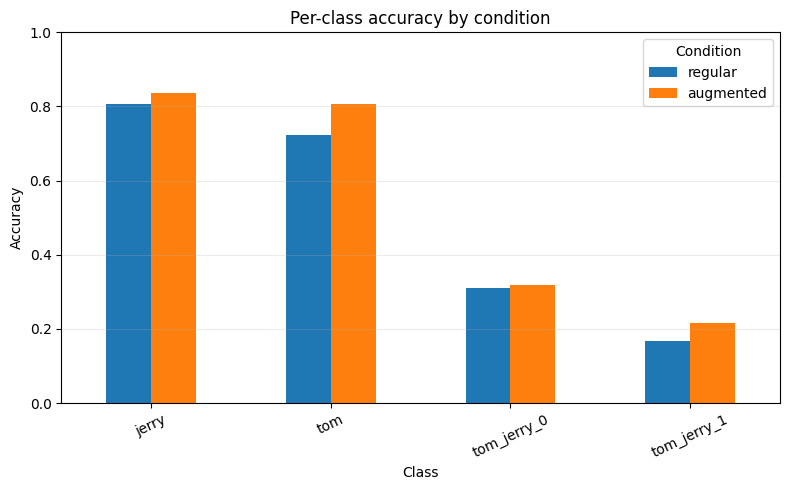

(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'Per-class accuracy by condition'}, xlabel='Class', ylabel='Accuracy'>)

In [764]:
classification_counts_table = pd.concat(
    [classification_counts(experiment, regular), classification_counts(experiment, augmented)],
    ignore_index=True,
)
display(classification_counts_table)
plot_per_class_accuracy(
    experiment, per_class, CONDITIONS,
    experiment_figures_dir / "per_class_accuracy.png",
)

Rank and plot the most common v3 confusion pairs.


,label,predicted,count,experiment,condition
18,tom_jerry_0,jerry,2174,v3,augmented
22,tom_jerry_1,tom,983,v3,augmented
15,tom,jerry,642,v3,augmented
21,tom_jerry_1,jerry,532,v3,augmented
19,tom_jerry_0,tom,412,v3,augmented
6,tom_jerry_0,jerry,2236,v3,regular
3,tom,jerry,1085,v3,regular
10,tom_jerry_1,tom,929,v3,regular
9,tom_jerry_1,jerry,671,v3,regular
7,tom_jerry_0,tom,380,v3,regular


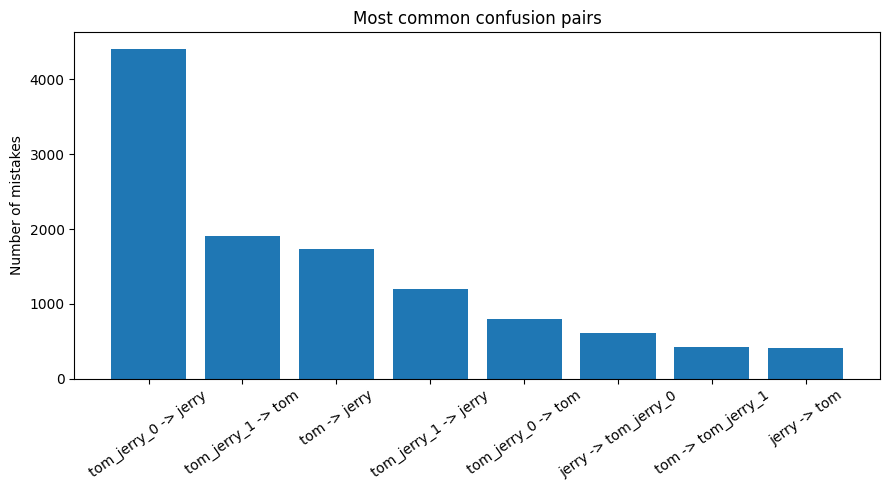

(<Figure size 900x500 with 1 Axes>,
 <Axes: title={'center': 'Most common confusion pairs'}, ylabel='Number of mistakes'>)

In [765]:
confusion_pairs_table = pd.concat(
    [confusion_pairs(experiment, regular), confusion_pairs(experiment, augmented)],
    ignore_index=True,
).sort_values(["experiment", "condition", "count"], ascending=[True, True, False])
confusion_pairs_table.to_csv(
    experiment_results_dir / "analysis_common_confusion_pairs.csv",
    index=False,
)
display(confusion_pairs_table.groupby("condition", group_keys=False).head(5))
plot_common_confusion_pairs(
    experiment, confusion_pairs_table,
    experiment_figures_dir / "common_confusion_pairs.png",
)

## v3 interpretation

V3 compares the Model 2 setup with light augmentation against the regular condition. Augmentation shows a clear improvement in the run-level results: mean test accuracy is about 0.593 for augmented training compared with 0.548 for regular training. The mean paired accuracy difference is about 0.045, and all matched seeds should be inspected in the paired plot to check how consistently that gain occurs.

The augmented condition also has a lower mean test loss, about 1.030 compared with 1.126 for regular training. The best checkpoint steps vary between seeds, so the validation curves and checkpoint summaries are important when interpreting this improvement rather than relying only on the final training step.

Class-level accuracy improves for every class under augmentation in the pooled results. The largest practical gains are for Tom and `tom_jerry_1`, although the combined-character classes remain substantially harder than Jerry and Tom. Confusion matrices and common confusion pairs should still be reported because the difficult classes continue to account for many errors.

Overall, v3 provides stronger evidence that the light augmentation used in Model 2 improves generalisation relative to its regular reference condition, while recognising that the difficult combined-character classes remain a limitation.


# v4 Analysis - Model 2 - Regular and Heavily Augmented


In [766]:
experiment = "v4"
experiment_results_dir = RESULTS_DIR / experiment
experiment_figures_dir = experiment_results_dir / "analysis_figures"
experiment_figures_dir.mkdir(exist_ok=True)
regular = load_condition(experiment, RESULTS_DIR, "regular", SEEDS)
augmented = load_condition(experiment, RESULTS_DIR, "augmented", SEEDS)

Read each v4 saved run file and save the individual results as a CSV table.


In [767]:
runs = individual_runs_table(experiment, [regular, augmented])
runs.to_csv(experiment_results_dir / "analysis_individual_runs.csv", index=False)
display(runs.style.format({"best_val_loss": "{:.4f}", "test_loss": "{:.4f}", "test_accuracy": "{:.4f}", "minutes": "{:.1f}"}))

,experiment,condition,seed,best_step,best_val_loss,test_loss,test_accuracy,minutes
0,v4,augmented,0,500,1.0762,1.0244,0.6134,40.1
1,v4,augmented,1,350,0.9732,0.9660,0.6061,36.5
2,v4,augmented,2,600,1.0548,0.9904,0.5936,41.1
3,v4,augmented,3,450,1.0854,1.0849,0.5977,40.3
4,v4,augmented,4,500,1.0595,1.0657,0.5907,41.3
5,v4,regular,0,300,1.1582,1.1899,0.5363,60.0
6,v4,regular,1,200,1.0436,1.0464,0.5652,41.7
7,v4,regular,2,150,1.1608,1.1642,0.5144,27.5
8,v4,regular,3,450,1.1088,1.0923,0.5750,40.8
9,v4,regular,4,600,1.1034,1.1346,0.5484,39.7


Calculate v4 condition-level summaries and compare accuracy for matched seeds.


In [768]:
summary = condition_summary(experiment, [regular, augmented])
paired = paired_accuracy(experiment, regular, augmented)
display(summary)
display(paired)
print(f"Mean paired accuracy difference: {paired['augmented_minus_regular'].mean():.4f}")

test_accuracy           test_loss          
                              mean       std      mean       std
experiment condition                                            
v4         augmented      0.600292  0.009310  1.026276  0.049781
           regular        0.547864  0.023922  1.125476  0.057212

condition        augmented   regular  augmented_minus_regular
experiment seed                                              
v4         0      0.613363  0.536327                 0.077035
           1      0.606061  0.565170                 0.040891
           2      0.593647  0.514421                 0.079226
           3      0.597663  0.575027                 0.022636
           4      0.590727  0.548375                 0.042351

Mean paired accuracy difference: 0.0524


Plot v4 validation loss and accuracy curves.


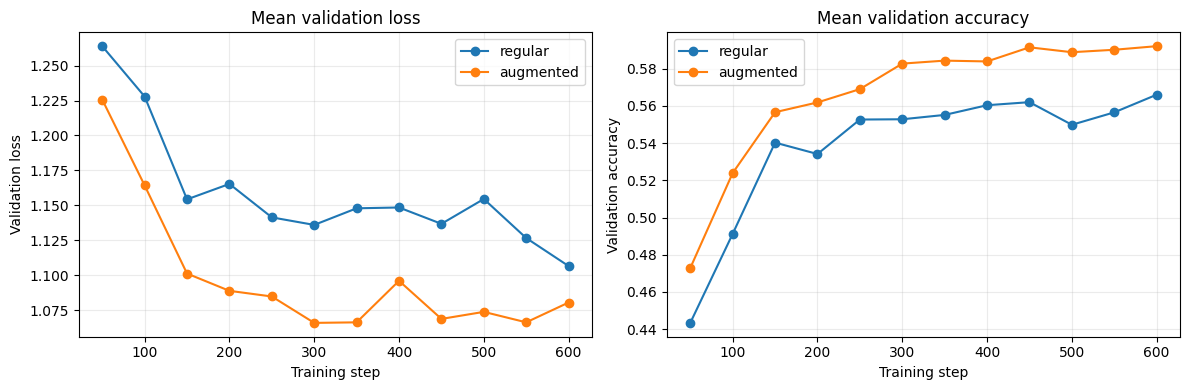

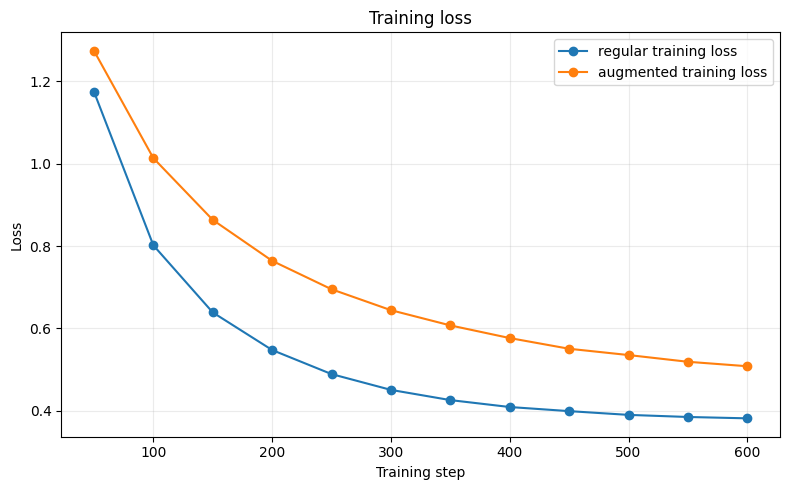

mean         std
experiment condition                   
v4         augmented  480.0   90.829511
           regular    340.0  185.067555

In [769]:
history_by_condition = {
    "regular": mean_validation_history(experiment, regular),
    "augmented": mean_validation_history(experiment, augmented),
}
plot_validation_curves(experiment, history_by_condition, experiment_figures_dir / "validation_curves.png")
plot_training_curves(experiment, history_by_condition, experiment_figures_dir / "training_curves.png")

best_steps = runs.groupby(["experiment", "condition"])["best_step"].agg(["mean", "std"])
display(best_steps)

Plot v4 test accuracy for each seed with condition mean and standard deviation.


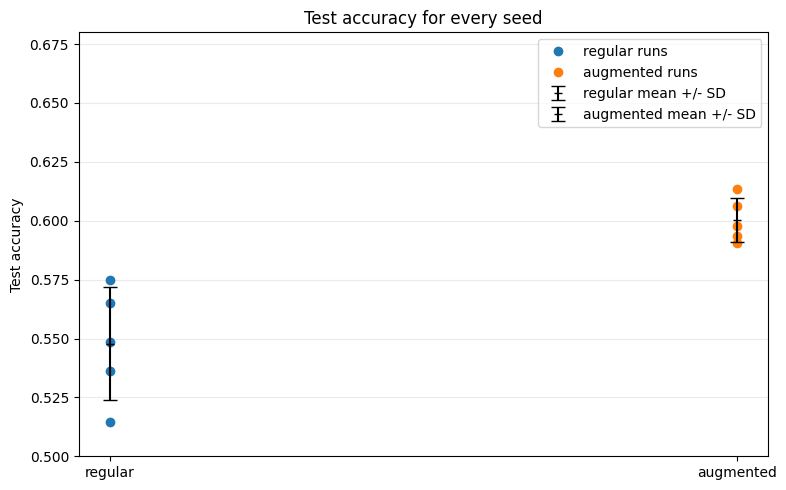

(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'Test accuracy for every seed'}, ylabel='Test accuracy'>)

In [770]:
plot_test_accuracy_by_seed(
    experiment, runs, CONDITIONS,
    experiment_figures_dir / "test_accuracy_by_seed.png",
)

Plot the v4 paired accuracy difference for each matched seed.


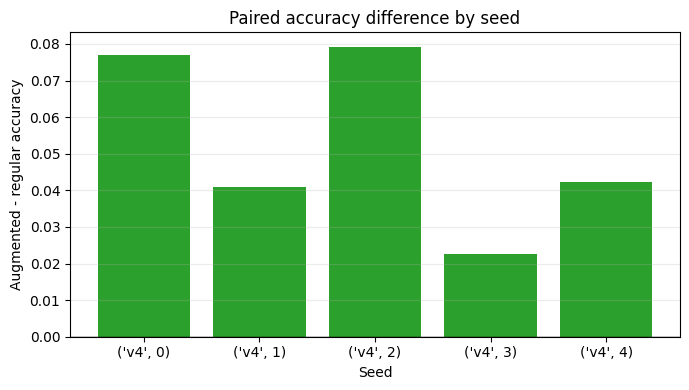

(<Figure size 700x400 with 1 Axes>,
 <Axes: title={'center': 'Paired accuracy difference by seed'}, xlabel='Seed', ylabel='Augmented - regular accuracy'>)

In [771]:
plot_paired_accuracy_difference(
    experiment, paired,
    experiment_figures_dir / "paired_accuracy_difference.png",
)

Create v4 pooled confusion matrices and per-class accuracy.


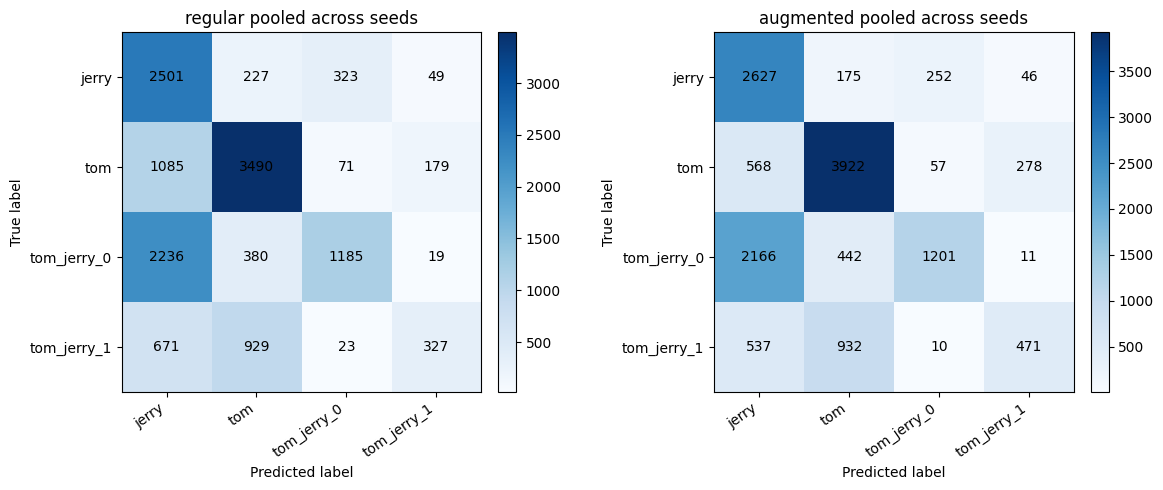

condition,augmented,regular
class,,
jerry,0.847419,0.806774
tom,0.812850,0.723316
tom_jerry_0,0.314398,0.310209
tom_jerry_1,0.241538,0.167692


In [772]:
confusion_matrices = {
    condition["name"]: confusion_matrix(experiment, condition)
    for condition in [regular, augmented]
}
plot_confusion_matrices(
    experiment, confusion_matrices,
    experiment_figures_dir / "pooled_confusion_matrices.png",
)
per_class = pd.concat(
    [per_class_accuracy(experiment, regular), per_class_accuracy(experiment, augmented)],
    ignore_index=True,
)
per_class.to_csv(experiment_results_dir / "analysis_per_class_accuracy.csv", index=False)
display(per_class.pivot(index="class", columns="condition", values="accuracy"))

Show v4 classification counts and per-class accuracy.


,experiment,condition,class,TP,FP,FN,TN
0,v4,regular,jerry,2501,3992,599,6603
1,v4,regular,tom,3490,1536,1335,7334
2,v4,regular,tom_jerry_0,1185,417,2635,9458
3,v4,regular,tom_jerry_1,327,247,1623,11498
4,v4,augmented,jerry,2627,3271,473,7324
5,v4,augmented,tom,3922,1549,903,7321
6,v4,augmented,tom_jerry_0,1201,319,2619,9556
7,v4,augmented,tom_jerry_1,471,335,1479,11410


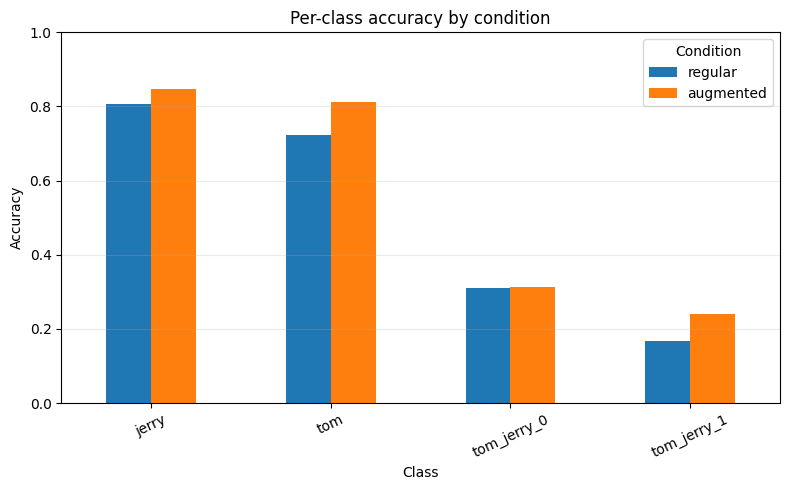

(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'Per-class accuracy by condition'}, xlabel='Class', ylabel='Accuracy'>)

In [773]:
classification_counts_table = pd.concat(
    [classification_counts(experiment, regular), classification_counts(experiment, augmented)],
    ignore_index=True,
)
display(classification_counts_table)
plot_per_class_accuracy(
    experiment, per_class, CONDITIONS,
    experiment_figures_dir / "per_class_accuracy.png",
)

Rank and plot the most common v4 confusion pairs.


,label,predicted,count,experiment,condition
18,tom_jerry_0,jerry,2166,v4,augmented
22,tom_jerry_1,tom,932,v4,augmented
15,tom,jerry,568,v4,augmented
21,tom_jerry_1,jerry,537,v4,augmented
19,tom_jerry_0,tom,442,v4,augmented
6,tom_jerry_0,jerry,2236,v4,regular
3,tom,jerry,1085,v4,regular
10,tom_jerry_1,tom,929,v4,regular
9,tom_jerry_1,jerry,671,v4,regular
7,tom_jerry_0,tom,380,v4,regular


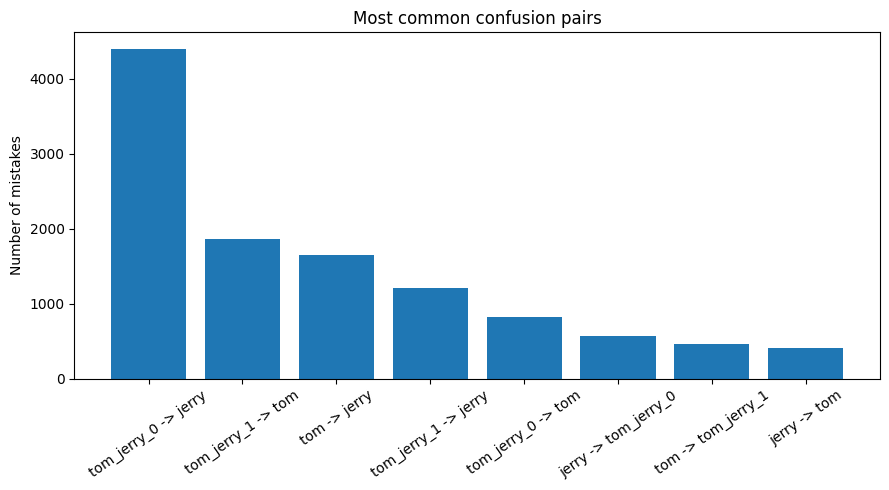

(<Figure size 900x500 with 1 Axes>,
 <Axes: title={'center': 'Most common confusion pairs'}, ylabel='Number of mistakes'>)

In [774]:
confusion_pairs_table = pd.concat(
    [confusion_pairs(experiment, regular), confusion_pairs(experiment, augmented)],
    ignore_index=True,
).sort_values(["experiment", "condition", "count"], ascending=[True, True, False])
confusion_pairs_table.to_csv(
    experiment_results_dir / "analysis_common_confusion_pairs.csv",
    index=False,
)
display(confusion_pairs_table.groupby("condition", group_keys=False).head(5))
plot_common_confusion_pairs(
    experiment, confusion_pairs_table,
    experiment_figures_dir / "common_confusion_pairs.png",
)

[READ] ## v4 interpretation

V4 compares the Model 2 setup with heavier augmentation against the regular condition. The augmented condition reaches a mean test accuracy of about 0.600 compared with 0.548 for regular training. The mean paired accuracy difference is about 0.052, which is larger than the corresponding v3 difference and should be checked against the individual seed results before drawing a broad conclusion.

Augmentation also lowers mean test loss from about 1.126 to 1.026. The augmented runs select checkpoints later on average, while the regular runs have more variation in their selected steps. This indicates that the heavier augmentation changes the training dynamics as well as the final performance.

Per-class accuracy improves for Jerry, Tom, and `tom_jerry_1` under augmentation. The `tom_jerry_0` result is nearly unchanged, so this class remains a weakness. The confusion matrices and confusion-pair counts are therefore important: a higher overall accuracy does not mean that all image categories are equally well recognised.

Overall, v4 shows the strongest average accuracy and test-loss improvement of the analysed experiments so far. The result should still be reported with the seed-level values, class-level metrics, and confusion analysis rather than as an overall accuracy claim alone.
